# WasteWise — MobileNetV3-Small baseline

This experiment evaluated MobileNetV3-Small as a lightweight baseline for
six-category TrashNet classification. ImageNet features were frozen while a new
linear classifier was trained, allowing comparison with the other architectures
under the same training budget.

## 1. Environment and project paths

The experiment used the scientific Python environment. Package versions and
project paths are recorded below.

In [1]:
from pathlib import Path
import os
import sys

# Set this only if the repository has moved and automatic discovery cannot find it.
ROOT_OVERRIDE = None
explicit_root = ROOT_OVERRIDE or os.environ.get("WASTEWISE_ROOT")
start = Path.cwd().resolve()
candidates = ([Path(explicit_root).expanduser()] if explicit_root else
              [start, *start.parents, Path.home() / "Projects" / "WasteWise"])
for candidate in candidates:
    candidate = candidate.resolve()
    if ((candidate / "src/experiment_data.py").is_file()
            and (candidate / "manifests/split_manifest.csv").is_file()):
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Set ROOT_OVERRIDE to the WasteWise project root and rerun this cell.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import experiment_data as datasets
from src import experiment_results as results

if Path(datasets.__file__).resolve().parent.parent != PROJECT_ROOT:
    raise RuntimeError("A different WasteWise checkout is cached. Restart this kernel.")
print("Project root: .")
print("Python interpreter:", Path(sys.executable).name)
display(results.package_table())



Project root: .
Python interpreter: python


,Version
Package,
torch,2.14.1
torchvision,0.29.1
numpy,2.5.3
pandas,3.0.6
Pillow,12.3.0
matplotlib,3.11.2
ipykernel,7.4.0


## 2. Experimental configuration

The classifier head was trained for five epochs with cross-entropy loss and
Adam. The settings below matched the other baselines, including seed 42.
The checkpoint with the highest validation macro-F1 was retained, with the
earlier epoch used in an exact tie.

In [2]:
MODEL_NAME = "mobilenetv3_small"
DISPLAY_NAME = "MobileNetV3-Small"
NOTEBOOK_NAME = "01_mobilenetv3.ipynb"
MODE = "reload"  # "review", "train", or "reload"
RUN_NAME = "baseline_seed42_5epochs"
RESTORE_CHECKPOINT = False
DEVICE_PREFERENCE = "auto"  # Apple MPS if available, otherwise CPU; "cpu" forces CPU.

CONFIG = {**results.BASELINE,
          "seed": 42, "loss": "CrossEntropyLoss", "optimizer": "Adam",
          "learning_rate": 0.001, "batch_size": 32, "epochs": 5}
if MODE not in {"review", "train", "reload"}:
    raise ValueError("Choose review, train, or reload.")
run = None
model = None
run_config = None
display(pd.Series(CONFIG, name="Setting").to_frame())
print("Mode:", MODE)
print("Results directory:", results.run_path(PROJECT_ROOT, MODEL_NAME, RUN_NAME).relative_to(PROJECT_ROOT))

,Setting
seed,42
loss,CrossEntropyLoss
optimizer,Adam
learning_rate,0.001
batch_size,32
epochs,5
weight_decay,0.0
num_workers,0
augmentation,none
head,single_linear_layer


Mode: reload
Results directory: results/experiments/mobilenetv3_small/baseline_seed42_5epochs


## 3. Training and validation data

The approved split supplied 1,765 training images and 378 validation images.
Keeping 43 accepted related-image groups within individual subsets reduced
leakage risk, although unresolved object relationships remained.

,Training,Validation
Category,,
cardboard,282,61
glass,348,75
metal,287,61
paper,416,89
plastic,336,72
trash,96,20
Total,1765,378


Class-to-index mapping: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
Approved split SHA-256: b1e09badb3d1347f7b2d934c5824b10daa7b57f5a4e9c06be89d05b56659546f


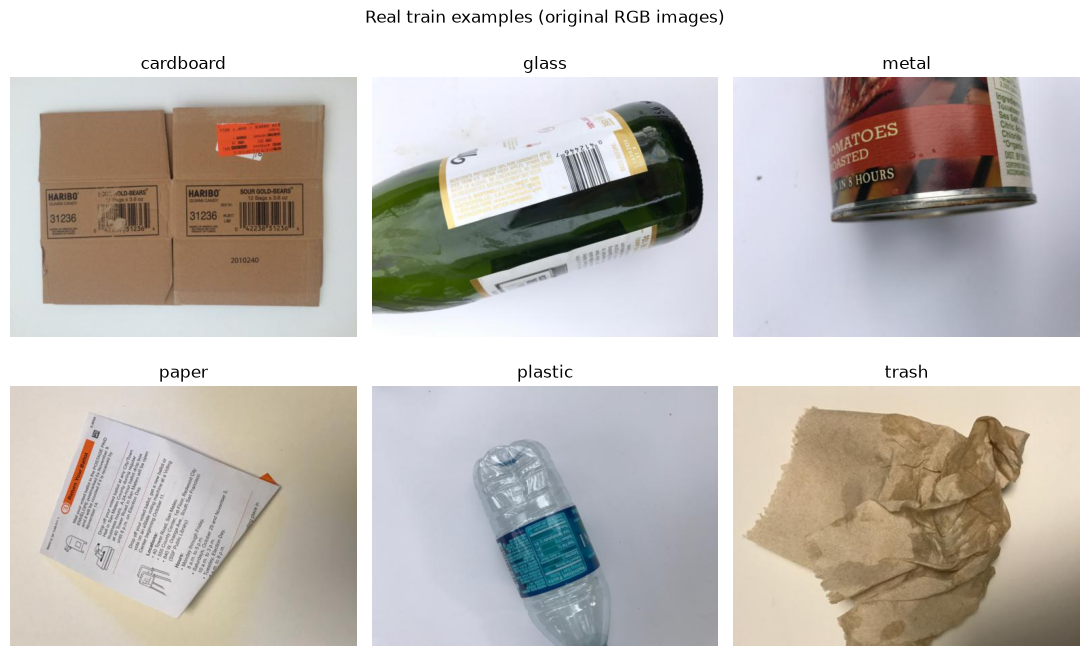

In [3]:
data = datasets.load_experiment_data(PROJECT_ROOT)
class_counts = datasets.dataset_table(data)
class_counts.loc["Total"] = class_counts.sum()
display(class_counts)
print("Class-to-index mapping:", {label: i for i, label in enumerate(data["classes"])})
print("Approved split SHA-256:", data["manifest_sha256"])
results.plot_examples(data, subset="train", seed=CONFIG["seed"])
plt.show()

## 4. Model and preprocessing

[MobileNetV3-Small](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html)
used Torchvision's `MobileNet_V3_Small_Weights.IMAGENET1K_V1` weights. Its feature
extractor and pooling were frozen, and its original classifier was replaced by
a six-output linear layer. The backbone remained in evaluation mode so
batch-normalization statistics stayed fixed.

Both subsets used bilinear resizing to a 256-pixel shorter edge, a 224 × 224
center crop, and ImageNet channel normalization. No augmentation was applied.

In [4]:
def build_model(pretrained=True):
    """This notebook's architecture; no model is built until the function is called."""
    from torch import nn
    from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

    weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1
    model = mobilenet_v3_small(weights=weights if pretrained else None)
    model.requires_grad_(False)
    feature_count = model.classifier[0].in_features
    model.classifier = nn.Linear(feature_count, len(data["classes"]))
    return model, model.classifier, weights.transforms(), weights

In [5]:
if MODE == "train":
    results.require_new_run(PROJECT_ROOT, MODEL_NAME, RUN_NAME)
    from src import experiment_training as training
    training.seed_everything(CONFIG["seed"])
    device = training.select_device(DEVICE_PREFERENCE)
    model, head, transform, weights = build_model(pretrained=True)
    run_config = training.make_config(
        data, MODEL_NAME, DISPLAY_NAME, RUN_NAME, model, head, weights, device,
        NOTEBOOK_NAME, CONFIG,
    )
elif MODE == "reload":
    run = results.load_run(PROJECT_ROOT, MODEL_NAME, RUN_NAME, data,
                           require_checkpoint=RESTORE_CHECKPOINT)
    run_config = run["config"]
    if RESTORE_CHECKPOINT:
        from src import experiment_training as training
        device = training.select_device(DEVICE_PREFERENCE)
        model, head, transform, weights = build_model(pretrained=False)
        model = training.restore_checkpoint(model, run, data, device)
        print("Checkpoint restored without training; recorded timings below are from the original run.")

if run_config is not None:
    display(pd.Series({key: run_config[key] for key in [
        "display_name", "weights", "device", "total_parameters", "trainable_parameters",
        "trainable_parameter_names", "preprocessing",
    ]}, name="Model information").to_frame())
    classifier_summary = run_config["architecture"].split("(classifier): ", 1)[1].splitlines()[0]
    print("Replacement classifier:", classifier_summary)
else:
    print("Architecture definition is ready. Model construction waits for train or checkpoint-reload mode.")

,Model information
display_name,MobileNetV3-Small
weights,MobileNet_V3_Small_Weights.IMAGENET1K_V1
device,mps
total_parameters,930470
trainable_parameters,3462
trainable_parameter_names,"[classifier.weight, classifier.bias]"
preprocessing,"{'resize_size': [256], 'crop_size': [224], 'in..."


Replacement classifier: Linear(in_features=576, out_features=6, bias=True)


## 5. Training progress

All five epochs were completed on Apple MPS. The saved history records the
losses, validation performance, and duration of each epoch. Macro-F1 gave each
category equal weight when selecting the checkpoint.

In [6]:
if MODE == "train":
    run = training.train_baseline(data, model, head, transform, run_config, device)
elif MODE == "reload":
    print("Loaded saved results; no training or new timing measurements were performed.")
else:
    print("Review mode: training has not been executed.")

if run is not None:
    display(run["history"])

Loaded saved results; no training or new timing measurements were performed.


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,epoch_seconds
0,1,1.237776,0.578470,0.925630,0.695767,0.610727,8.417476
1,2,0.824894,0.733144,0.744428,0.767196,0.726519,4.686178
2,3,0.690965,0.781870,0.657309,0.801587,0.725068,4.554457
3,4,0.612632,0.798300,0.607602,0.814815,0.775948,4.565835
4,5,0.563302,0.820397,0.576753,0.817460,0.762992,4.485101


## 6. Learning curves

Training and validation loss decreased throughout the five epochs. Validation
macro-F1 peaked at epoch 4 and fell slightly at epoch 5, despite further
improvements in loss and overall accuracy. Epoch 4 was therefore retained
under the predefined selection rule.

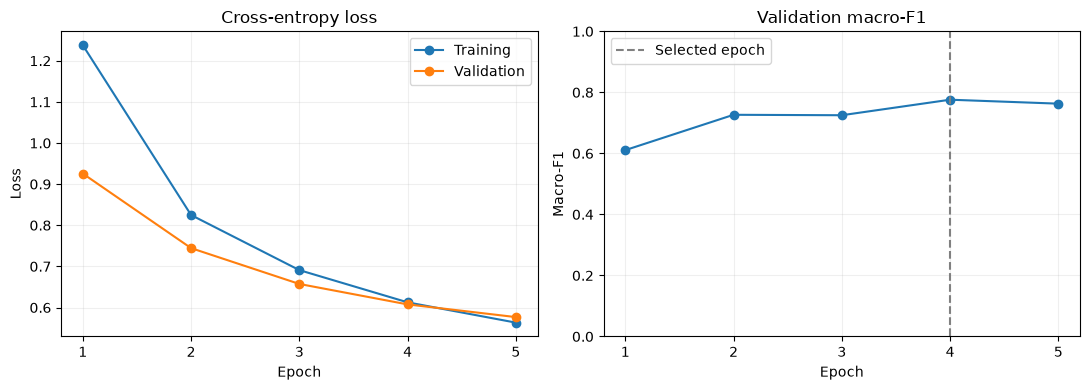

In [7]:
if run is not None:
    results.plot_history(run)
    plt.show()
else:
    print("Learning curves will appear after a real run is trained or reloaded.")

## 7. Validation metrics and confusion matrix

Cardboard achieved the highest F1 (0.8527); the other non-trash categories ranged
from 0.8029 to 0.8455. Trash was the weakest category (F1 0.5000), with only 9 of
20 validation images recognized. Its high one-versus-rest accuracy included
true negatives and therefore obscured this low recall.

,Validation result
accuracy,0.814815
macro_f1,0.775948
weighted_f1,0.812590
validation_loss,0.607602
n_validation,378.000000
best_epoch,4.000000


,precision,recall,f1,support,one_vs_rest_accuracy
class,,,,,
cardboard,0.8088,0.9016,0.8527,61,0.9497
glass,0.8158,0.8267,0.8212,75,0.9286
metal,0.8387,0.8525,0.8455,61,0.9497
paper,0.8242,0.8427,0.8333,89,0.9206
plastic,0.8462,0.7639,0.8029,72,0.9286
trash,0.5625,0.4500,0.5000,20,0.9524


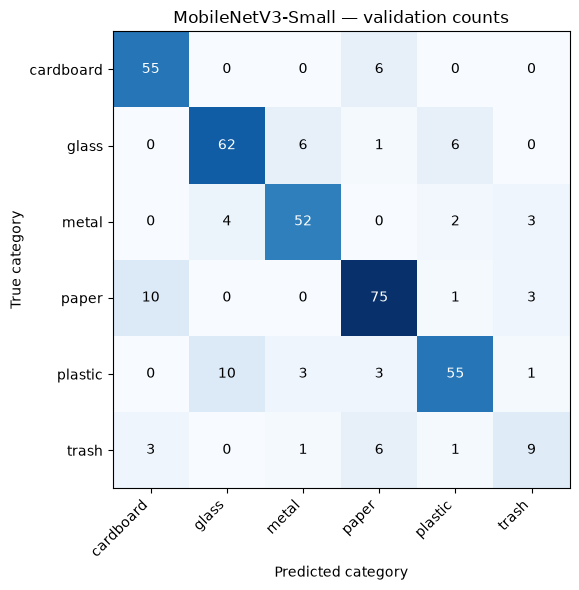

In [8]:
if run is not None:
    metrics = run["metrics"]
    display(pd.Series({key: metrics[key] for key in [
        "accuracy", "macro_f1", "weighted_f1", "validation_loss", "n_validation", "best_epoch"
    ]}, name="Validation result").to_frame())
    display(pd.DataFrame(metrics["per_class"]).set_index("class").round(4))
    results.plot_confusion(run)
    plt.show()
else:
    print("Validation metrics are pending an actual experiment.")

## 8. Correct predictions and error analysis

Plastic → glass and paper → cardboard were the most frequent confusions
(10 images each); each reverse direction occurred six times. The grids show
six low-confidence correct predictions and the eight most confident errors.

The errors included transparent containers and printed cardboard. A plastic
bottle was classified as glass with 93.2% confidence, illustrating that a high
softmax score did not ensure a correct material label.

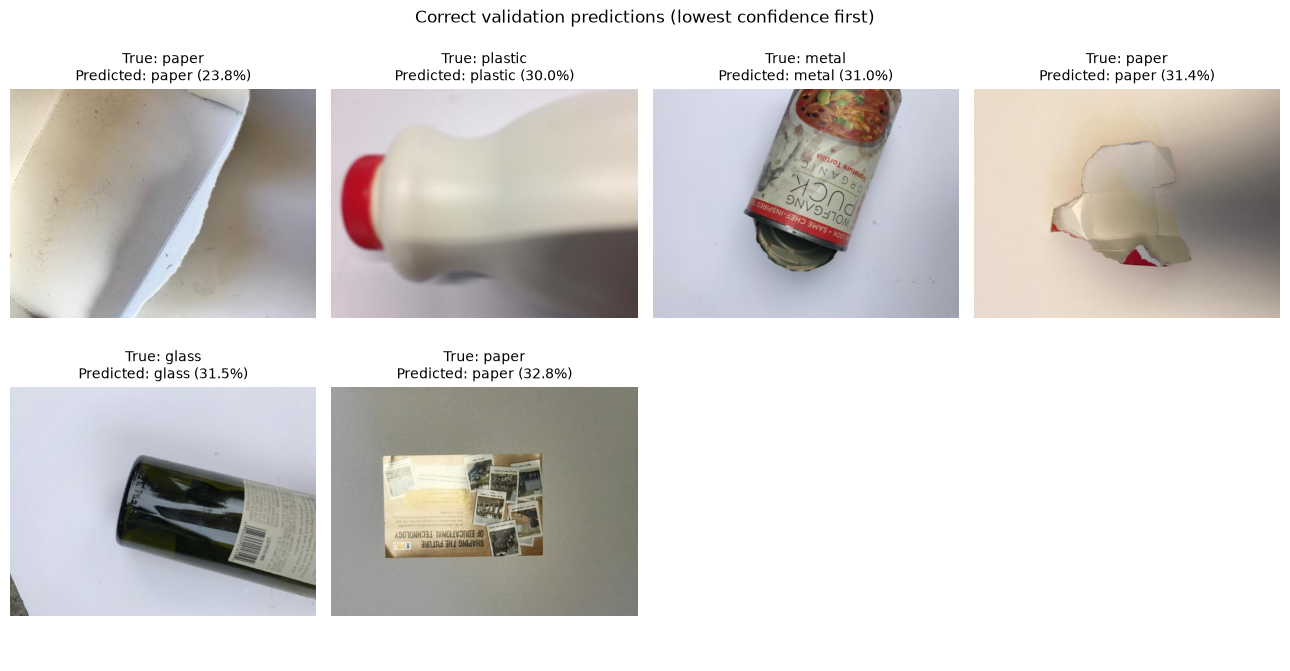

,path,true_label,predicted_label,confidence,correct
356,plastic/plastic94.jpg,plastic,glass,0.931720,False
98,glass/glass294.jpg,glass,metal,0.904793,False
375,trash/trash61.jpg,trash,cardboard,0.899211,False
357,plastic/plastic95.jpg,plastic,glass,0.877755,False
26,cardboard/cardboard266.jpg,cardboard,paper,0.776273,False
344,plastic/plastic436.jpg,plastic,metal,0.755924,False
10,cardboard/cardboard166.jpg,cardboard,paper,0.742592,False
128,glass/glass470.jpg,glass,plastic,0.717893,False


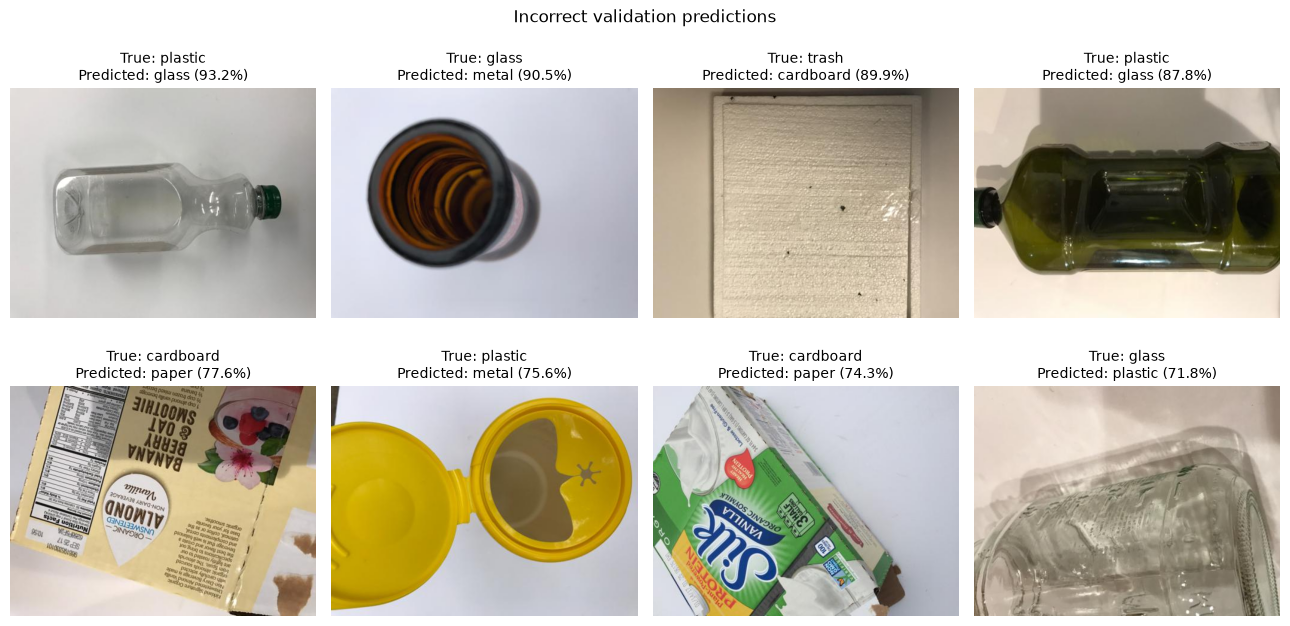

,true_label,predicted_label,Images
0,plastic,glass,10
1,paper,cardboard,10
2,cardboard,paper,6
3,trash,paper,6
4,glass,plastic,6


In [9]:
if run is not None:
    correct_examples = results.prediction_examples(run, correct=True, limit=6)
    results.plot_predictions(data, correct_examples, "Correct validation predictions (lowest confidence first)")
    plt.show()
    error_examples = results.prediction_examples(run, correct=False, limit=8)
    has_errors = (~run["predictions"]["correct"]).any()
    title = "Incorrect validation predictions" if has_errors else "No errors recorded: low-confidence correct predictions"
    display(error_examples[["path", "true_label", "predicted_label", "confidence", "correct"]])
    results.plot_predictions(data, error_examples, title)
    plt.show()
    display(results.confusion_pairs(run))
else:
    print("Prediction examples require real saved validation predictions.")

## 9. Training time and local inference latency

Timing used batch size one on Apple MPS, with 10 warm-up and 50 timed passes over
20 seeded validation images. Forward timing covered the model alone; end-to-end
timing included image decoding, preprocessing, transfer, and prediction.

Training took 26.71 seconds. Median end-to-end latency was 4.66 ms, consistent
with fast local inference under these warm-run conditions. Model startup,
camera capture, and the application interface were not measured.

In [10]:
if run is not None:
    timing = run["metrics"]["latency"]
    print(f"Total training time: {run['metrics']['training_seconds']:.2f} seconds")
    print("Measured device:", timing["device"])
    latency_table = pd.DataFrame({
        name: {key: timing[name][key] for key in ["mean_ms", "median_ms", "p95_ms"]}
        for name in ["forward", "end_to_end"]
    }).T.rename_axis("Timing scope")
    display(latency_table.round(3))
    print("Completed run:", run["directory"].relative_to(PROJECT_ROOT))
else:
    print("No training duration or inference latency has been measured yet.")

Total training time: 26.71 seconds
Measured device: mps


,mean_ms,median_ms,p95_ms
Timing scope,,,
forward,3.183,2.995,4.056
end_to_end,4.956,4.660,6.413


Completed run: results/experiments/mobilenetv3_small/baseline_seed42_5epochs


## 10. Observations and interpretation

The selected checkpoint achieved 81.48% validation accuracy and macro-F1 0.7759.
Frozen ImageNet features supported a fast baseline, but performance was uneven
across materials. These results came from one seed and one split; they do not
establish generalization to new physical objects or camera images. The held-out
test set was not evaluated.